In [9]:
import pandas as pd

df = pd.read_csv("/home/student/Downloads/ds-ev-range-analysis/data/EV_Cleaned_2025.csv")

In [10]:
features = ["battery_capacity_kWh","efficiency_wh_per_km","top_speed_kmh","acceleration_0_100_s","seats","torque_nm"]
X = df[features]
y = df["range_km"]

In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [12]:
print("Original dataset:", X.shape)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Original dataset: (478, 6)
Training data: (382, 6)
Testing data: (96, 6)


In [14]:
print("Missing values in X_train:")
print(X_train.isnull().sum())
print("\nMissing values in X_test:")
print(X_test.isnull().sum())
print("\nMissing values in y_train:")
print(y_train.isnull().sum())

Missing values in X_train:
battery_capacity_kWh    0
efficiency_wh_per_km    0
top_speed_kmh           0
acceleration_0_100_s    0
seats                   0
torque_nm               6
dtype: int64

Missing values in X_test:
battery_capacity_kWh    0
efficiency_wh_per_km    0
top_speed_kmh           0
acceleration_0_100_s    0
seats                   0
torque_nm               1
dtype: int64

Missing values in y_train:
0


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", LinearRegression())
])

In [16]:
print("Missing values in X_train:")
print(X_train.isnull().sum())
print("\nMissing values in X_test:")
print(X_test.isnull().sum())
print("\nMissing values in y_train:")
print(y_train.isnull().sum())

Missing values in X_train:
battery_capacity_kWh    0
efficiency_wh_per_km    0
top_speed_kmh           0
acceleration_0_100_s    0
seats                   0
torque_nm               6
dtype: int64

Missing values in X_test:
battery_capacity_kWh    0
efficiency_wh_per_km    0
top_speed_kmh           0
acceleration_0_100_s    0
seats                   0
torque_nm               1
dtype: int64

Missing values in y_train:
0


In [17]:
X_train_imputed = model.named_steps["imputer"].fit_transform(X_train)

print("Missing values before imputation:")
print(X_train.isnull().sum())

print("\nMissing values after imputation:")
print(pd.DataFrame(X_train_imputed, columns=X_train.columns).isnull().sum())

Missing values before imputation:
battery_capacity_kWh    0
efficiency_wh_per_km    0
top_speed_kmh           0
acceleration_0_100_s    0
seats                   0
torque_nm               6
dtype: int64

Missing values after imputation:
battery_capacity_kWh    0
efficiency_wh_per_km    0
top_speed_kmh           0
acceleration_0_100_s    0
seats                   0
torque_nm               0
dtype: int64


In [18]:
model.fit(X_train, y_train)
print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [19]:
y_pred = model.predict(X_test)
print("Predicted EV ranges:")
print(y_pred)

Predicted EV ranges:
[500.87206755 497.01036287 134.36744794 447.11039722 421.36160703
 280.57204466 391.38238795 359.02813424 322.84306346 315.27729468
 528.53448724 298.29283808 160.61220706 497.72678095 256.45155133
 371.60612148 509.81037656 238.21115627 256.45155133 482.97715306
 233.2600481  219.10241918 434.06230438 424.27880829 235.54954834
 486.99537999 516.22309809 305.74687259 362.23431576 531.23336127
 467.24836435 302.24011292 283.5266633  284.67073046 360.56847869
 504.27192802 392.46837222 425.42602717 424.84816371 332.40538185
 363.52828392 446.26802503 347.21051373 490.38684712 421.03668846
 356.03909414 509.14341576 278.91941261 283.14627485 560.29611717
 489.50080745 416.52581962 399.86663653 504.2429441  350.77810003
 448.02190138 469.02699228 301.43029781 513.8430078  468.40040211
 360.44261226 438.2823524  196.89010606 446.38361564 435.83567062
 507.26249702 440.04915034 427.82296697 505.60177219 293.51064411
 272.33438677 409.73066389 373.82704005 447.01647808 37

In [20]:
print("Total EV records:", len(df))
print("Training predictions:", len(X_train))
print("Testing predictions:", len(y_pred))

Total EV records: 478
Training predictions: 382
Testing predictions: 96


Evaluate your model
We'll calculate four important evaluation metrics.Evaluate your model

In [21]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

In [22]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 26.28404300818597
Mean Squared Error: 1085.00474087814
Root Mean Squared Error: 32.93941014769602
R2 Score: 0.8974646237810848


Visualize actual vs predicted range
This graph helps us see how close your predictions are to the actual EV ranges.

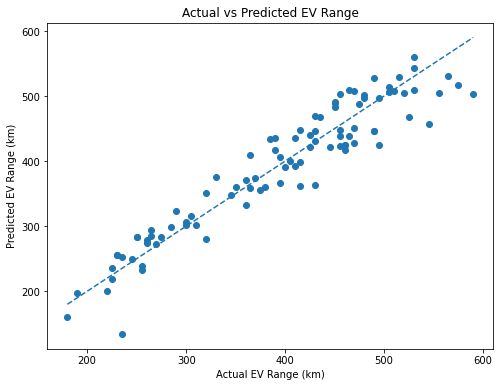

In [23]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual EV Range (km)")
plt.ylabel("Predicted EV Range (km)")
plt.title("Actual vs Predicted EV Range")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--")
plt.show()

Train a Random Forest Regression model
Your project guidelines require comparing multiple models. We'll use Random Forest Regression as our second model.
What is Random Forest Regression?
Random Forest uses multiple decision trees to make predictions. It combines their results to produce a final prediction.
Unlike Linear Regression, it can learn more complex relationships between EV specifications and driving range.

In [32]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

Training the model

In [33]:
rf_model.fit(X_train, y_train)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Generating predictions

In [34]:
rf_pred = rf_model.predict(X_test)
print("Random Forest Predicted Ranges:")
print(rf_pred)

Random Forest Predicted Ranges:
[486.3        511.125      246.48666667 467.44166667 447.85
 308.25       388.4        340.81666667 290.65       303.15
 489.5        311.05       180.         476.15       231.98333333
 356.375      544.8        225.7        231.98333333 489.95
 230.8        221.         423.1        452.15       230.25
 488.2        532.65       312.05       363.85       538.75
 466.82416667 310.2        290.75       280.35       372.39166667
 523.75       405.         463.85       412.46666667 335.025
 355.2        445.8        350.1        486.4        445.05
 355.3        474.25       261.4        267.95       537.45
 483.7        415.15       384.7625     507.5        334.15
 439.95       433.24       303.4        488.85       475.69166667
 352.8        447.7        230.9        439.80833333 416.45
 459.9        451.35       444.4        513.2        273.15
 284.6        383.07       358.1        464.84166667 355.55
 538.4        458.75       448.85       401.95   

Calculate Evaluation Metrics

In [35]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)
print("Random Forest MAE:", rf_mae)
print("Random Forest MSE:", rf_mse)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2 Score:", rf_r2)

Random Forest MAE: 18.791001984126986
Random Forest MSE: 633.3630782038339
Random Forest RMSE: 25.166705747948694
Random Forest R2 Score: 0.9401457716634124


Visualising Model Comparison

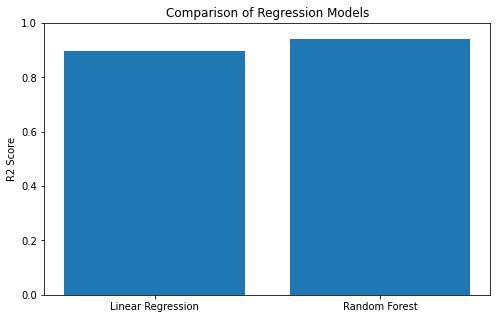

In [36]:
models = ["Linear Regression", "Random Forest"]
scores = [r2, rf_r2]
plt.figure(figsize=(8, 5))
plt.bar(models, scores)
plt.ylabel("R2 Score")
plt.title("Comparison of Regression Models")
plt.ylim(0, 1)
plt.show()

identifying which EV specifications contribute most to predicting driving range.
Feature Importance Analysis
What is feature importance?
Feature importance tells us which input features are most useful to the Random Forest model when making predictions.
For example, we can investigate whether battery capacity, efficiency or top speed contributes more to predicting EV range.

In [37]:
feature_importance = rf_model.named_steps["regressor"].feature_importances_
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": feature_importance})
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False)
print(importance_df)

                Feature  Importance
0  battery_capacity_kWh    0.811356
1  efficiency_wh_per_km    0.085276
2         top_speed_kmh    0.046629
3  acceleration_0_100_s    0.033782
4                 seats    0.011818
5             torque_nm    0.011139


Visualize feature importance

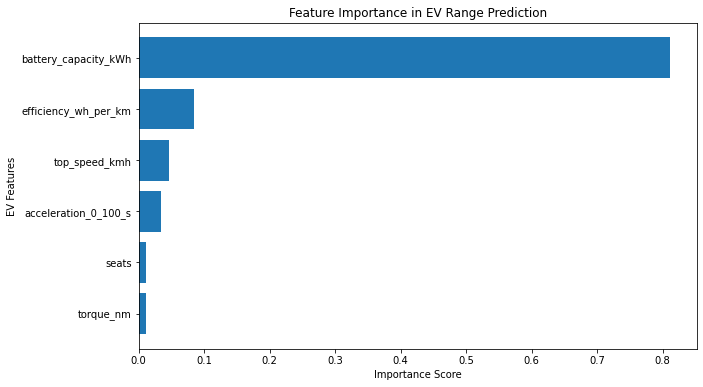

In [38]:
plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"])
plt.xlabel("Importance Score")
plt.ylabel("EV Features")
plt.title("Feature Importance in EV Range Prediction")
plt.gca().invert_yaxis()
plt.show()

Save the model

In [39]:
import joblib
joblib.dump(rf_model, "/home/student/Downloads/ds-ev-range-analysis/models/random_forest_model.pkl")
print("Model saved successfully!")

Model saved successfully!


Verifying the model

In [41]:
import os
print(os.path.exists("/home/student/Downloads/ds-ev-range-analysis/models/random_forest_model.pkl"))

True
